# PC04 — Phân tích hồ sơ phân khúc và xây dựng lập luận nghiệp vụ

## Mục tiêu nghiệp vụ
Sau khi có nhãn, câu hỏi quan trọng là **cụm đại diện cho hành vi gì, bên trong đa dạng đến đâu và nên nghiên cứu hành động nào**. Không thể chỉ xem một bảng trung vị rồi gọi nhóm M cao là VIP hay nhóm R cao là đã rời bỏ.

PC04 trình bày quy mô/đóng góp, phân bố từng trục, mức khó phân biệt, hành vi hủy/trả với hai mẫu số, đặc điểm giỏ hàng và cơ cấu sản phẩm. Đồng thời đối chiếu k=2/3/4 để xem phần chi tiết thêm có mang ý nghĩa sử dụng hay chỉ làm tăng số nhãn.

## Nguyên tắc diễn giải
1. Đọc cùng lúc R, F, M và phạm vi lịch sử delivered.
2. Nhận xét có số liệu và mẫu số; phân biệt quan sát với giải thích nguyên nhân.
3. Tách nhãn cụm thống kê, tên mô tả và giả thuyết hành động.
4. Giữ trường hợp khó phân biệt và giới hạn dữ liệu, không xóa để kể câu chuyện rõ hơn.

Nhãn số là cách đánh dấu nhóm, không có thứ tự giá trị tương lai. Các đề xuất dưới đây là hướng nghiên cứu, chưa là chính sách đã được doanh nghiệp duyệt hoặc thử nghiệm hiệu quả.


## Bản đồ ký hiệu và nguyên tắc đọc công thức

| Ký hiệu | Ý nghĩa trong notebook |
|---|---|
| c / i | Khách / chỉ số điểm dữ liệu; đọc định nghĩa tại từng công thức |
| o | Một order_id; không phải một dòng sản phẩm |
| E | Tập khách đủ điều kiện RFM delivered |
| T | Mốc31/12/2022 |
| n | Số khách của tập đang phân tích |
| k, Cj | Số cụm và tập khách của cụm j |
| R/F/M | Giá trị thô trên cùng tập đơn đủ điều kiện |
| x, z | Giá trị trước/sau biến đổi theo ngữ cảnh |
| μ, σ | Trung bình/tâm và độ lệch chuẩn, định nghĩa cụ thể cạnh công thức |

Một ký hiệu có thể dùng ở cấp khác trong một công thức khác; mỗi mục đều giải thích phạm vi và mẫu số. Đọc đơn vị, thời gian và trạng thái trước khi so số. Công thức minh họa và kết quả dự án được tách rõ. Các hàm Python giữ tên tiếng Anh để tái sử dụng; nội dung trình bày bằng tiếng Việt.


## Chuẩn bị môi trường và nguồn dữ liệu

Chạy với dữ liệu mô hình đã lưu trong data/model/phan_khuc/v1. Để huấn luyện lại từ PC03, đặt biến môi trường DATATHON_MODEL_RUN thành một tên lượt mới.

In [1]:
from pathlib import Path
import sys
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))

from ham_dung_chung import segmentation_study
Study = segmentation_study().Study
share_table = segmentation_study().share_table
concentration = segmentation_study().concentration
distribution = segmentation_study().distribution
from ham_dung_chung import rfm_features
rfm = rfm_features().rfm
from ham_dung_chung import segmentation_transform
feature_matrix = segmentation_transform().feature_matrix
from ham_dung_chung import segmentation_defaults
require = segmentation_defaults().require
FEATURES = segmentation_defaults().FEATURES
CUTOFF = segmentation_defaults().CUTOFF
MODEL_LABEL = os.environ.get("DATATHON_MODEL_RUN", "v1")
study = Study(ROOT, "PC04")
pd.set_option('display.max_columns',20)
print('Phần phân tích:', study.part, '| Lượt mô hình:', MODEL_LABEL)

Phần phân tích: PC04 | Thư mục kết quả: /workspace/scratch/1f9612b45e80/professional/DA_PC/reports/segmentation/professional_v1/PC04


## PC04.1 — Quy mô phân khúc và đóng góp giá trị

**Câu hỏi:** nhóm đông khách có phải nhóm đóng góp nhiều Net nhất?

Với n khách đủ điều kiện, quy mô và đóng góp nhóm j:

$$CustomerShare_j=\frac{|C_j|}{n},\qquad NetShare_j=\frac{\sum_{c\in C_j}M_c}{\sum_{c\in E}M_c}.$$

Hai cột có cùng khoảng0–1 nhưng khác mẫu số. Một nhóm nhỏ khách có thể có NetShare lớn. Các nhóm rời nhau nên mỗi cột cộng thành1; đây là kiểm tra bảo toàn, không kiểm định mô hình có giá trị kinh doanh.

Tên số được sắp theo M trung bình tăng dần để trình bày. Số2 không mặc nhiên tốt gấp đôi số1; không so trực tiếp nhãn số giữa hai lần huấn luyện. Bảng còn báo trung vị R/F/M để tránh trung bình bị đuôi kéo mạnh.

**Cách đọc:** bắt đầu từ số khách và tỷ trọng, sau đó xem nhóm đóng góp nhờ nhiều lần mua, đơn lớn hay cả hai. M chỉ là Net delivered sau giảm, chưa trừ đầy đủ hoàn trả/chi phí, nên không gọi NetShare là tỷ trọng lợi nhuận.


,Nhóm,Số khách,R trung vị,F trung vị,M trung vị,Tổng Net,TB tỷ trọng cancelled/khách,TB tỷ trọng returned/khách,TB tỷ trọng có returns/khách,TB tỷ trọng thiếu shipment/khách,Số SP khác nhau trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,34498,2307.0,1.0,29651.965,1.435208e+09,0.061616,0.036944,0.036891,0.000000,2.0,0.405310,0.114650
1,1,40342,598.0,5.0,124473.995,5.614874e+09,0.075082,0.045350,0.045252,0.001875,6.0,0.473971,0.448538
2,2,10275,244.0,19.0,477244.080,5.468093e+09,0.082397,0.050480,0.050340,0.000975,20.0,0.120719,0.436812


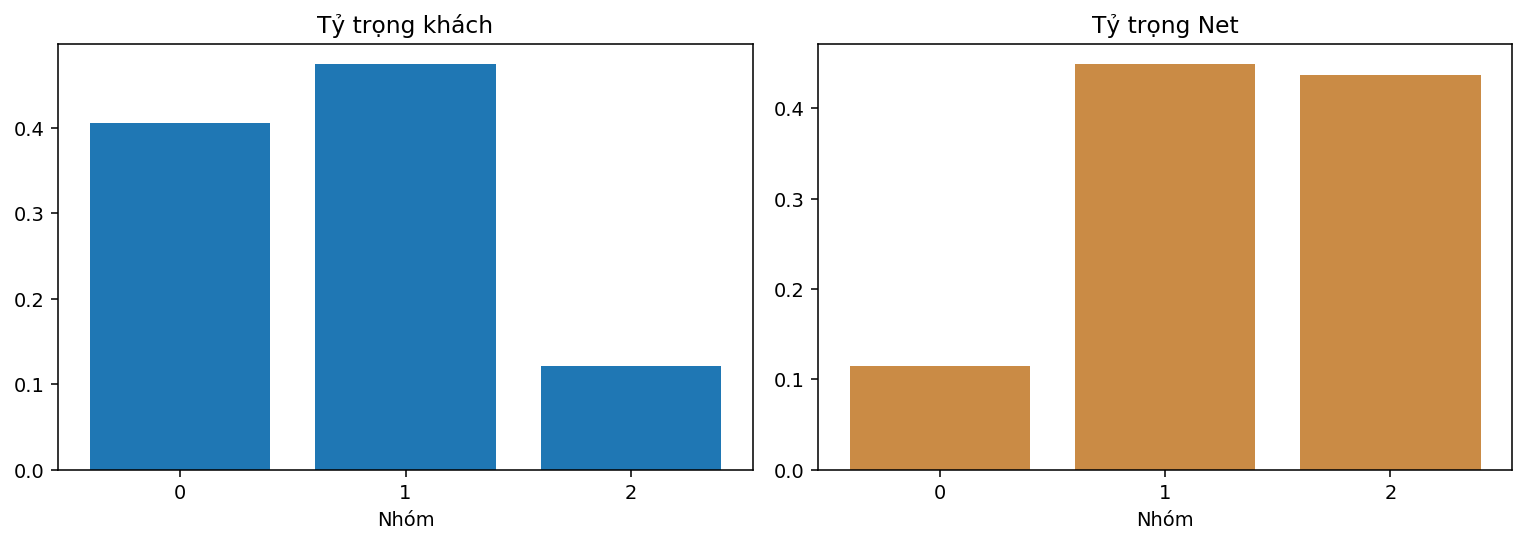

Tỷ trọng Net là giá trị delivered sau giảm tích lũy, không lợi nhuận hay thực thu. Không kết luận nhóm nhỏ là không quan trọng.

In [2]:
manifest=study.use_model(MODEL_LABEL);a=study.a.copy()
profiles=pd.read_csv(study.modelbase/'cluster_profiles.csv')
study.table('cluster_profiles','Hồ sơ gốc các nhóm',profiles)
fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(profiles.cluster.astype(str),profiles.customer_share);axes[0].set(title='Tỷ trọng khách',xlabel='Nhóm');axes[1].bar(profiles.cluster.astype(str),profiles.Monetary_share,color='#ca8b45');axes[1].set(title='Tỷ trọng Net',xlabel='Nhóm');study.fig('cluster_shares','Quy mô và đóng góp nhóm',fig)
study.note('Tỷ trọng Net là giá trị delivered sau giảm tích lũy, không lợi nhuận hay thực thu. Không kết luận nhóm nhỏ là không quan trọng.')

## PC04.2 — Độ phân tán bên trong và vùng giao giữa nhóm

**Câu hỏi:** hai nhóm có trung vị khác nhau thì mọi khách có khác nhau rõ không?

Báo P10/P25/P50/P75/P90 của mỗi biến trong mỗi cụm. Khoảng P25–P75 chứa phần giữa của phân bố theo quy ước phân vị, không phải độ tin cậy của trung vị. Boxplot ẩn điểm ngoài hàng rào để đọc hình không có nghĩa đã xóa khách khỏi phân tích.

Với hai khoảng IQR $[L_A,U_A]$ và $[L_B,U_B]$, độ dài phần giao:

$$Overlap=\max(0,\min(U_A,U_B)-\max(L_A,L_B)).$$

Đây là độ dài theo đơn vị biến, **không phải tỷ lệ khách bị gán sai**. R của hai nhóm có thể giao, nhưng kết hợp F/M vẫn phân biệt được; ngược lại IQR không giao không chứng minh toàn bộ hai phân bố rời nhau.

**Ví dụ:** IQR nhóm A=[10,30], nhóm B=[20,50] giao một đoạn dài10. Không thể nói10% khách trùng, vì chưa đếm các quan sát cụ thể và chưa biết phân bố trong đoạn đó.

**Ý nghĩa nghiệp vụ:** không thiết kế cùng một ưu đãi cho mọi khách chỉ vì cùng nhãn. Các khách gần ranh giới cần được hiểu là có hành vi trung gian; dùng thêm hồ sơ cá nhân hợp lệ và điều kiện vận hành trước hành động.


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [3]:
# VÍ DỤ GIẢ LẬP: độ dài giao IQR không phải tỷ lệ khách.
toy_left=(10.,30.);toy_right=(20.,50.);toy_overlap=max(0,min(toy_left[1],toy_right[1])-max(toy_left[0],toy_right[0]));assert toy_overlap==10
study.table('VD08_IQR','Ví dụ giả lập — giao hai khoảng',pd.DataFrame([{'IQR A':'[10,30]','IQR B':'[20,50]','Độ dài giao':toy_overlap,'Ý nghĩa':'10 đơn vị biến, không10% khách'}]))

Out[3]: 
     IQR A    IQR B  Độ dài giao                         Ý nghĩa
0  [10,30]  [20,50]         10.0  10 đơn vị biến, không10% khách


,IQR A,IQR B,Độ dài giao,Ý nghĩa
0,"[10,30]","[20,50]",10.0,"10 đơn vị biến, không10% khách"


<ipython-input-4-f445f7d29d57>:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  values=[g[col].astype(float).to_numpy() for _,g in a.groupby('cluster')];ax.boxplot(values,labels=[str(c) for c in sorted(a.cluster.unique())],showfliers=False);ax.set(title=col+' — không vẽ điểm ngoài box',xlabel='Nhóm')
<ipython-input-4-f445f7d29d57>:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  values=[g[col].astype(float).to_numpy() for _,g in a.groupby('cluster')];ax.boxplot(values,labels=[str(c) for c in sorted(a.cluster.unique())],showfliers=False);ax.set(title=col+' — không vẽ điểm ngoài box',xlabel='Nhóm')
<ipython-input-4-f445f7d29d57>:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotli

,Nhóm,Đặc trưng,P10,P25,P50,P75,P90
0,0,Recency,1625.000,1826.0000,2307.000,2854.0000,3409.000
1,0,Frequency,1.000,1.0000,1.000,2.0000,4.000
2,0,Monetary,5468.304,12219.0275,29651.965,59104.2525,94502.225
3,1,Recency,127.000,258.0000,598.000,1002.0000,1320.000
4,1,Frequency,1.000,3.0000,5.000,8.0000,11.000
5,1,Monetary,25685.452,61872.6850,124473.995,205637.6175,275851.835
6,2,Recency,47.000,123.0000,244.000,509.0000,833.600
7,2,Frequency,14.000,16.0000,19.000,24.0000,32.000
8,2,Monetary,340576.674,393894.0000,477244.080,611022.6850,792823.720


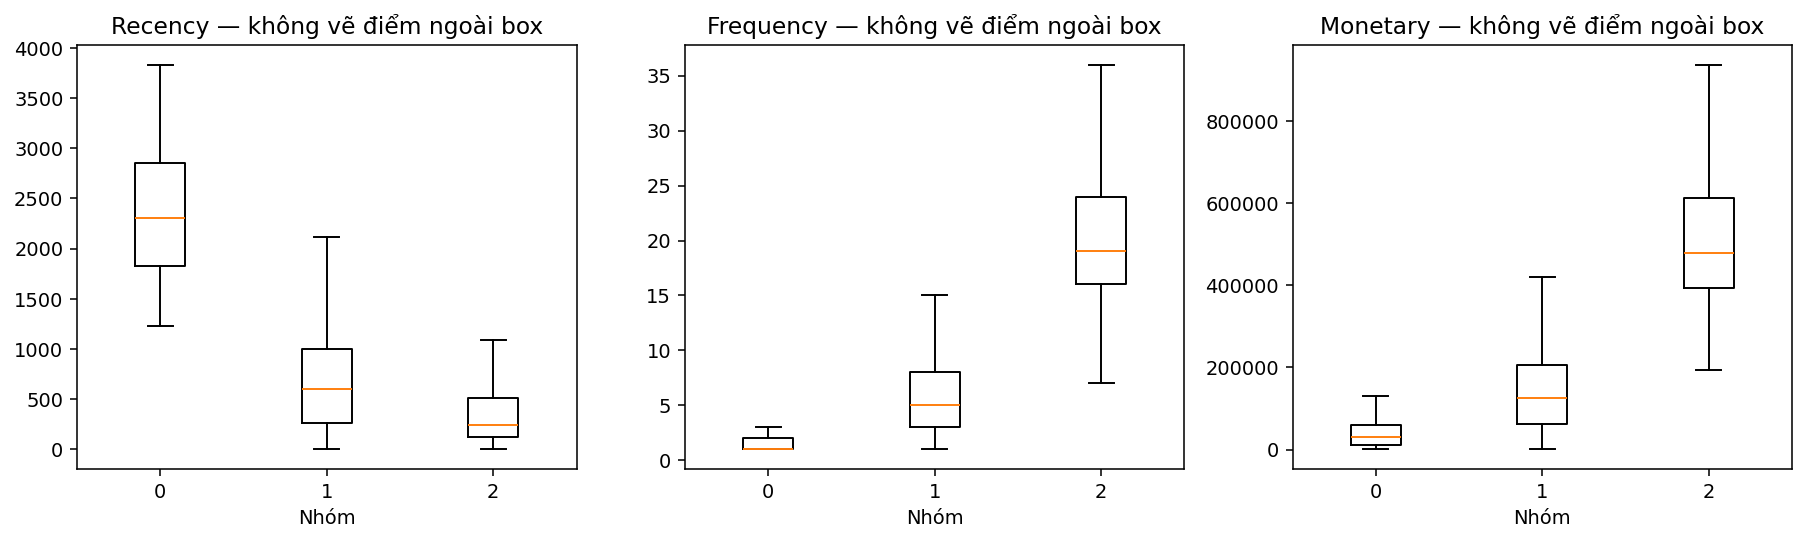

Nhóm không đồng nhất hoàn toàn. Cần đọc các biến đồng thời; ranh giới KMeans là khoảng cách đa biến trong không gian đã chuẩn hóa.

,Cặp nhóm,Đặc trưng,IQR trái dưới,IQR trái trên,IQR phải dưới,IQR phải trên,Độ dài giao IQR
0,0–1,Recency,1826.0000,2854.0000,258.000,1002.0000,0.0
1,0–1,Frequency,1.0000,2.0000,3.000,8.0000,0.0
2,0–1,Monetary,12219.0275,59104.2525,61872.685,205637.6175,0.0
3,0–2,Recency,1826.0000,2854.0000,123.000,509.0000,0.0
4,0–2,Frequency,1.0000,2.0000,16.000,24.0000,0.0
5,0–2,Monetary,12219.0275,59104.2525,393894.000,611022.6850,0.0
6,1–2,Recency,258.0000,1002.0000,123.000,509.0000,251.0
7,1–2,Frequency,3.0000,8.0000,16.000,24.0000,0.0
8,1–2,Monetary,61872.6850,205637.6175,393894.000,611022.6850,0.0


IQR giao theo một trục không phủ định phân tách đa biến; IQR không giao cũng không bảo đảm mọi khách của hai nhóm tách rời. Không biến độ dài giao thành tỷ lệ khách nhầm nhóm.

In [4]:
rows=[]
for cl,g in a.groupby('cluster'):
 for col in FEATURES:
  q=g[col].astype(float).quantile([.1,.25,.5,.75,.9]);rows.append({'cluster':cl,'Đặc trưng':col,'P10':q.loc[.1],'P25':q.loc[.25],'P50':q.loc[.5],'P75':q.loc[.75],'P90':q.loc[.9]})
quantiles=study.table('cluster_quantiles','Phân vị theo từng nhóm',pd.DataFrame(rows))
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,col in zip(axes,FEATURES):
 values=[g[col].astype(float).to_numpy() for _,g in a.groupby('cluster')];ax.boxplot(values,labels=[str(c) for c in sorted(a.cluster.unique())],showfliers=False);ax.set(title=col+' — không vẽ điểm ngoài box',xlabel='Nhóm')
study.fig('within_cluster_spread','Độ phân tán trong nhóm',fig)
study.note('Nhóm không đồng nhất hoàn toàn. Cần đọc các biến đồng thời; ranh giới KMeans là khoảng cách đa biến trong không gian đã chuẩn hóa.')
from itertools import combinations
intersection=[]
for left,right in combinations(sorted(a.cluster.unique()),2):
 for col in FEATURES:
  ql=a.loc[a.cluster.eq(left),col].astype(float).quantile([.25,.75]);qr=a.loc[a.cluster.eq(right),col].astype(float).quantile([.25,.75]);overlap=max(0,min(ql.iloc[1],qr.iloc[1])-max(ql.iloc[0],qr.iloc[0]))
  intersection.append({'Cặp nhóm':str(left)+'–'+str(right),'Đặc trưng':col,'IQR trái dưới':ql.iloc[0],'IQR trái trên':ql.iloc[1],'IQR phải dưới':qr.iloc[0],'IQR phải trên':qr.iloc[1],'Độ dài giao IQR':overlap})
study.table('marginal_iqr_overlap','Phần giao IQR từng trục giữa cặp nhóm',pd.DataFrame(intersection))
study.note('IQR giao theo một trục không phủ định phân tách đa biến; IQR không giao cũng không bảo đảm mọi khách của hai nhóm tách rời. Không biến độ dài giao thành tỷ lệ khách nhầm nhóm.')

## PC04.3 — Nhóm nào phân tách rõ, nhóm nào có nhiều trường hợp trung gian?

Silhouette trung bình toàn mẫu có thể che cụm có nhiều điểm khó phân biệt. Vì vậy tính lại $s(i)$ trên đúng mẫu đánh giá và tổng hợp riêng từng nhóm.

Tỷ lệ điểm âm trong mẫu thuộc cụm j:

$$NegativeShare_j=\frac{\#\{i\in C_j\cap S:s(i)<0\}}{|C_j\cap S|}.$$

S là tập mã mẫu, không phải toàn bộ khách. Mẫu số từng cụm khác nhau; cần báo số điểm mẫu để không so một nhóm rất ít điểm như có độ chắc chắn ngang nhóm lớn.

Một điểm âm nghĩa là trung bình khoảng cách đến một cụm khác nhỏ hơn khoảng cách nội cụm theo phép đo đang dùng. Nó không phải nhãn sai đã xác minh, không chứng minh dữ liệu lỗi và không cho phép gọi $1-NegativeShare$ là accuracy.

**Cách dùng:** nếu cụm có nhiều điểm âm, xem phân bố, biến đổi và đối thủ k khác; không tự xóa điểm âm để tăng S. Bước này bổ sung góc nhìn độ phân tách, chưa tạo quy tắc chấp nhận/loại từng khách trong vận hành.


,Nhóm,sample_customers,silhouette_mean,silhouette_median,negative_share
0,0,2015,0.548810,0.611802,0.000000
1,1,2357,0.396373,0.448056,0.039881
2,2,628,0.405154,0.463920,0.019108


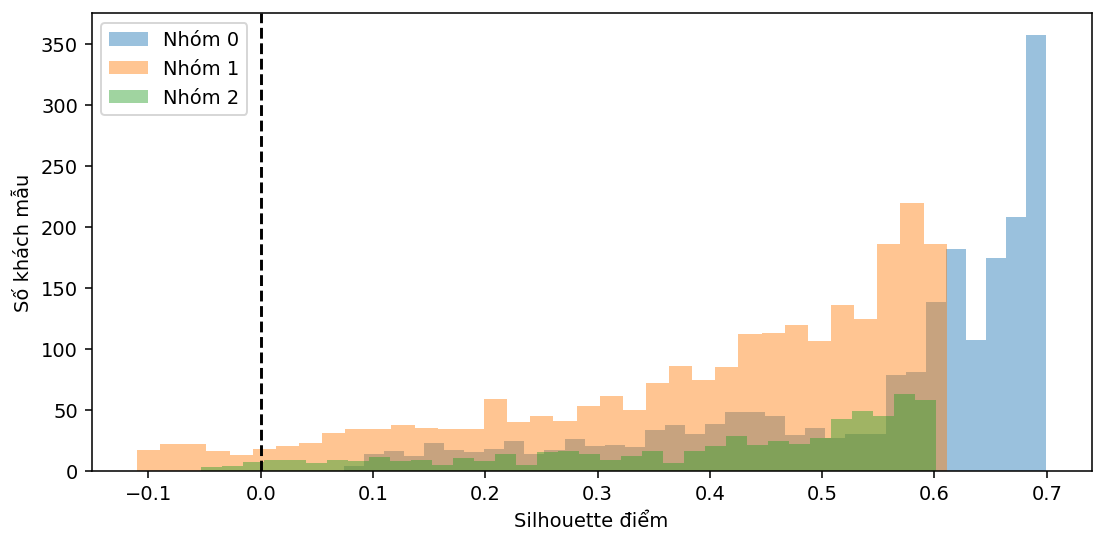

Tỷ lệ điểm mẫu silhouette âm=2.12%. Không gọi 1−tỷ lệ này là accuracy vì không có nhãn đúng.

In [5]:
from sklearn.metrics import silhouette_samples
from threadpoolctl import threadpool_limits
sample_ids=pd.read_csv(study.modelbase/'silhouette_sample.csv',dtype={'customer_id':str}).customer_id
s=a.set_index('customer_id').loc[sample_ids].reset_index();variant=manifest['selected']['variant']
x,sc=feature_matrix(a,variant);positions=pd.Index(a.customer_id).get_indexer(sample_ids)
with threadpool_limits(limits=1):ss=silhouette_samples(x[positions],s.cluster.to_numpy())
s['silhouette']=ss
q=s.groupby('cluster').agg(sample_customers=('customer_id','size'),silhouette_mean=('silhouette','mean'),silhouette_median=('silhouette','median'),negative_share=('silhouette',lambda v:(v<0).mean())).reset_index()
study.table('silhouette_by_cluster','Mức phân tách trên mẫu theo nhóm',q)
fig,ax=plt.subplots(figsize=(8,4))
for cl,g in s.groupby('cluster'):ax.hist(g.silhouette,bins=35,alpha=.45,label='Nhóm '+str(cl))
ax.axvline(0,color='black',linestyle='--');ax.set(xlabel='Silhouette điểm',ylabel='Số khách mẫu');ax.legend();study.fig('silhouette_distribution','Phần phân tách và khó phân biệt',fig)
study.note(f'Tỷ lệ điểm mẫu silhouette âm={np.mean(ss<0):.2%}. Không gọi 1−tỷ lệ này là accuracy vì không có nhãn đúng.')

## PC04.4 — Hủy/trả: hai trọng số và hai câu hỏi nghiệp vụ

**Câu hỏi:** đang quan tâm “khách điển hình” hay “đơn điển hình” trong nhóm?

Khách c có $h_c$ đơn cancelled và $N_c$ tổng đơn mọi trạng thái. Tỷ trọng theo khách là $r_c=h_c/N_c$. Với cụm j:

$$MeanCustomerRate_j=\frac{1}{|C_j|}\sum_{c\in C_j}r_c,$$

$$PooledOrderRate_j=\frac{\sum_{c\in C_j}h_c}{\sum_{c\in C_j}N_c}.$$

Tỷ lệ gộp chính là trung bình $r_c$ có trọng số $N_c$. Công thức đầu cho mỗi khách trọng số bằng nhau; công thức sau cho mỗi đơn trọng số bằng nhau. Chúng không phải hai cách làm tròn của cùng một chỉ tiêu.

**Ví dụ giả lập:** khách A hủy1/1đơn, khách B hủy0/9đơn. Trung bình theo khách=(100%+0%)/2=50%, nhưng gộp đơn=1/10=10%. Hai con số đều đúng với hai câu hỏi khác nhau. Thứ tự giữa các cụm có thể đảo khi đổi mẫu số.

Returned theo nhãn Orders và có chi tiết returns được báo riêng. Tỷ lệ delivered thiếu shipment dùng số đơn delivered, không tổng mọi trạng thái. Dữ liệu này mô tả snapshot; không suy ý định hủy, gian lận hoặc xác suất đơn tương lai sẽ hỏng.

**Quyết định diễn giải:** luôn ghi mẫu số cạnh bảng và kết luận. Nếu nhóm nhiều F có tỷ trọng hủy khác, cần đọc cơ hội phát sinh đơn và đặc điểm đặt hàng trước khi đánh giá chất lượng khách.


### Minh họa tính tay có kiểm chứng — tách khỏi dữ liệu thật

Ô sau dùng dữ liệu giả lập với biến `toy_`, đối chiếu kết quả mong đợi hoặc thư viện. Chúng không tham gia huấn luyện. Sau ví dụ là phép phân tích trên dữ liệu dự án.

In [6]:
# VÍ DỤ GIẢ LẬP: thay trọng số có thể đảo thứ tự nhóm.
toy_rates=pd.DataFrame({'Nhóm ví dụ':['A','A','B','B'],'Khách ví dụ':['a1','a2','b1','b2'],'Đơn hủy':[1,0,2,2],'Tổng đơn':[1,9,5,5]});toy_rates['Tỷ trọng khách']=toy_rates['Đơn hủy']/toy_rates['Tổng đơn'];toy_summary=[]
for g,t in toy_rates.groupby('Nhóm ví dụ'):
 toy_summary.append({'Nhóm ví dụ':g,'TB theo khách':t['Tỷ trọng khách'].mean(),'Gộp theo đơn':t['Đơn hủy'].sum()/t['Tổng đơn'].sum()})
toy_summary=pd.DataFrame(toy_summary);assert np.isclose(toy_summary.iloc[0]['TB theo khách'],.5) and np.isclose(toy_summary.iloc[0]['Gộp theo đơn'],.1)
study.table('VD09_khach','Ví dụ giả lập — tỷ lệ từng khách',toy_rates)
study.table('VD09_mau_so','Ví dụ giả lập — nhómA cao hơn theo khách nhưng thấp hơn theo đơn',toy_summary)

Out[6]: 
  Nhóm ví dụ  TB theo khách  Gộp theo đơn
0          A            0.5           0.1
1          B            0.4           0.4


,Nhóm ví dụ,Khách ví dụ,Đơn hủy,Tổng đơn,Tỷ trọng khách
0,A,a1,1,1,1.0
1,A,a2,0,9,0.0
2,B,b1,2,5,0.4
3,B,b2,2,5,0.4


,Nhóm ví dụ,TB theo khách,Gộp theo đơn
0,A,0.5,0.1
1,B,0.4,0.4


In [7]:
rows=[]
for cl,g in a.groupby('cluster'):
 rows.append({'cluster':cl,'Số khách':len(g),'TB tỷ trọng cancelled/khách':g.cancelled_share.mean(),'Tỷ trọng cancelled gộp đơn':g.cancelled_orders.sum()/g.total_orders.sum(),'TB tỷ trọng returned/khách':g.returned_share.mean(),'Tỷ trọng returned gộp đơn':g.returned_orders.sum()/g.total_orders.sum(),'Khách có đơn thiếu shipment':int(g.delivered_missing_shipment_share.gt(0).sum()),'TB thiếu shipment/khách':g.delivered_missing_shipment_share.mean()})
behavior=study.table('behavior_denominators','Hai mẫu số và cờ theo nhóm',pd.DataFrame(rows))
study.note('Khách mua nhiều có nhiều cơ hội ghi nhận hủy/trả. Tỷ trọng cao hơn chưa chứng minh nhóm kém chất lượng, gian lận hoặc nguyên nhân đến từ khách.')
mean_order=behavior.sort_values('TB tỷ trọng cancelled/khách').cluster.astype(int).tolist()
pooled_order=behavior.sort_values('Tỷ trọng cancelled gộp đơn').cluster.astype(int).tolist()
study.note(f'Thứ tự nhóm theo cancelled tăng dần: trung bình theo khách={mean_order}; gộp theo đơn={pooled_order}. Hai thứ tự khác nhau cho thấy kết luận “nhóm hủy nhiều nhất” phụ thuộc câu hỏi và mẫu số; không chọn một mẫu số sau khi thấy kết quả thuận lợi.')

,Nhóm,Số khách,TB tỷ trọng cancelled/khách,Tỷ trọng cancelled gộp đơn,TB tỷ trọng returned/khách,Tỷ trọng returned gộp đơn,Khách có đơn thiếu shipment,TB thiếu shipment/khách
0,0,34498,0.061616,0.094139,0.036944,0.056711,0,0.000000
1,1,40342,0.075082,0.090031,0.045350,0.054373,305,0.001875
2,2,10275,0.082397,0.085554,0.050480,0.052306,208,0.000975


Khách mua nhiều có nhiều cơ hội ghi nhận hủy/trả. Tỷ trọng cao hơn chưa chứng minh nhóm kém chất lượng, gian lận hoặc nguyên nhân đến từ khách.

Thứ tự nhóm theo cancelled tăng dần: trung bình theo khách=[0, 1, 2]; gộp theo đơn=[2, 1, 0]. Hai thứ tự khác nhau cho thấy kết luận “nhóm hủy nhiều nhất” phụ thuộc câu hỏi và mẫu số; không chọn một mẫu số sau khi thấy kết quả thuận lợi.

## PC04.5 — Giỏ hàng, độ rộng giao dịch và tập trung nội bộ

**Câu hỏi:** nhóm M cao do mua thường xuyên hay do mỗi đơn lớn; giá trị có tập trung vào ít khách trong nhóm không?

Ở cấp khách:

$$AOV_c=\frac{M_c}{F_c},\qquad UnitsPerOrder_c=\frac{\sum_{o\in D_c}Quantity_o}{F_c}.$$

Báo trung vị các chỉ tiêu theo khách trong cụm. Không gọi trung vị AOV khách là giá trị trung bình của toàn bộ đơn. Số sản phẩm khác nhau là số mã product_id phân biệt trong các đơn đủ điều kiện; mua nhiều đơn tạo thêm cơ hội gặp mã mới.

Top10% nội bộ cụm được chọn riêng trong mỗi cụm theo M giảm dần. Vì số khách, phân bố và danh sách top khác nhau, tỷ trọng này mô tả tập trung bên trong, không cho biết nhóm nào đáng đầu tư hơn một cách độc lập.

**Cách đọc:** F cao và AOV tương tự nhóm khác gợi ý giá trị tích lũy đến nhiều từ số lần mua; AOV cao với F thấp gợi ý quy mô đơn khác. Đây là mô tả định nghĩa và dữ liệu, chưa phải nguyên nhân hoặc tiềm năng tăng trưởng. Cần chi phí, biên hàng và mục tiêu kinh doanh trước khi gọi nhóm là sinh lời cao.


In [8]:
rows=[]
for cl,g in a.groupby('cluster'):
 top=concentration(g).loc[lambda d:d.top_customer_fraction.eq(.1),'monetary_share'].iloc[0]
 rows.append({'cluster':cl,'AOV trung vị':g.average_order_value.median(),'Số lượng/đơn trung vị':g.units_per_delivered_order.median(),'Số sản phẩm khác nhau trung vị':g.distinct_products.median(),'Tỷ trọng Net top10% trong nhóm':top})
study.table('basket_and_concentration','Giỏ hàng và tập trung nội bộ',pd.DataFrame(rows))
study.note('AOV=M/F phụ thuộc RFM; breadth tăng theo số cơ hội mua. Chưa thể gọi là sở thích đa dạng hoặc nhạy giá nếu thiếu kiểm soát tần suất/cơ hội.')

,Nhóm,AOV trung vị,Số lượng/đơn trung vị,Số sản phẩm khác nhau trung vị,Tỷ trọng Net top10% trong nhóm
0,0,17688.128333,5.000000,2.0,0.314164
1,1,23026.396250,4.857143,6.0,0.228045
2,2,25324.892222,5.038462,20.0,0.187857


AOV=M/F phụ thuộc RFM; breadth tăng theo số cơ hội mua. Chưa thể gọi là sở thích đa dạng hoặc nhạy giá nếu thiếu kiểm soát tần suất/cơ hội.

## PC04.6 — Cơ cấu danh mục: kiểm mạch kể bằng dữ liệu giao dịch

**Câu hỏi:** khác biệt nhóm còn đi cùng cơ cấu sản phẩm nào trong phạm vi quan sát?

Gán nhóm khách về đơn delivered, rồi nối xuống dòng hàng bằng quan hệ nhiều dòng–một đơn. Chỉ cộng quantity và line_net; **không cộng lại Monetary cấp khách sau JOIN**.

Với danh mục g và cụm j:

$$NetShare_{j,g}=\frac{\sum_{i\in(j,g)}LineNet_i}{\sum_{i\in j}LineNet_i}.$$

Tương tự tỷ trọng quantity dùng quantity ở cả tử và mẫu. Hai tỷ trọng có thể khác do đơn giá; không trộn “bán nhiều” theo lượng với “đóng góp cao” theo tiền. Tổng line_net qua mọi danh mục/cụm phải khớp tổng M trước JOIN.

Danh mục là thuộc tính tham chiếu hiện có; hiệu lực lịch sử chưa được xác minh. Các chênh lệch cơ cấu gắn với tập giao dịch đã quan sát, không tự chứng minh sở thích cố định, độ nhạy giá hoặc tác động của chiến dịch. Nếu thấy một nhóm nghiêng một danh mục, đó là câu hỏi để nghiên cứu thêm sau khi kiểm độ phủ và thời gian.


In [9]:
o=study.orders();keys=o.loc[o.order_status.eq('delivered') & o.order_date.le(CUTOFF),['order_id','customer_id']].merge(a[['customer_id','cluster']],on='customer_id',validate='many_to_one')
items=pd.read_csv(ROOT/'data/processed/order_items_common.csv',dtype=str,usecols=['order_id','quantity','category','line_net'],keep_default_na=False)
joined=items.merge(keys,on='order_id',how='inner',validate='many_to_one');joined['quantity']=pd.to_numeric(joined.quantity);joined['line_net']=joined.line_net.map(Decimal)
cat=joined.groupby(['cluster','category']).agg(units=('quantity','sum'),net=('line_net',lambda x:sum(x,Decimal(0)))).reset_index();cat['net']=cat.net.astype(float);cat['units_share_in_cluster']=cat.units/cat.groupby('cluster').units.transform('sum');cat['net_share_in_cluster']=cat.net/cat.groupby('cluster').net.transform('sum')
require(np.isclose(cat.net.sum(),a.Monetary.sum()),'Mất/nhân tiền khi JOIN dòng hàng')
study.table('category_mix','Cơ cấu danh mục theo nhóm',cat)
study.note('Danh mục common dùng thông tin danh mục hiện có; hiệu lực lịch sử chưa xác minh. Khác biệt cơ cấu là mô tả giao dịch, không chứng minh sở thích cố định hay tác động marketing.')

,Nhóm,category,units,net,units_share_in_cluster,net_share_in_cluster
0,0,Casual,9588,3.511574e+07,0.029288,0.024467
1,0,GenZ,15731,3.107925e+07,0.048053,0.021655
2,0,Outdoor,133164,2.373434e+08,0.406774,0.165372
3,0,Streetwear,168883,1.131670e+09,0.515884,0.788506
4,1,Casual,39306,1.601167e+08,0.034451,0.028517
5,1,GenZ,68055,1.341207e+08,0.059648,0.023887
6,1,Outdoor,387498,7.577168e+08,0.339632,0.134948
7,1,Streetwear,646077,4.562920e+09,0.566269,0.812649
8,2,Casual,36563,1.538618e+08,0.033311,0.028138
9,2,GenZ,49469,9.800342e+07,0.045069,0.017923


Danh mục common dùng thông tin danh mục hiện có; hiệu lực lịch sử chưa xác minh. Khác biệt cơ cấu là mô tả giao dịch, không chứng minh sở thích cố định hay tác động marketing.

## PC04.7 — So sánh k=2,3,4 bằng cấu trúc khách thực tế

**Câu hỏi:** thêm cụm tạo ra một nhóm có hồ sơ sử dụng được hay chỉ tách nhỏ để chỉ số thay đổi?

Giữ phép biến đổi, seed và cấu hình; fit lại từng k. Bảng chéo giữa hai phân hoạch đếm:

$$n_{ab}=\#\{c:label_{k_1}(c)=a,\ label_{k_2}(c)=b\}.$$

Tổng mọi ô phải bằng số khách chung; tổng hàng/cột khớp quy mô nhóm tương ứng. Số nhãn không có quan hệ một-một, đặc biệt khi k khác nhau. Vì vậy ô ngoài đường chéo không phải số khách “đổi nhóm sai”.

K-Means tối ưu lại tất cả tâm/ràng buộc khi k đổi, không phải cây phân cấp. Một nhóm k3 có thể nhận khách từ cả hai nhóm k2; phải đọc bảng chéo thay vì giả định chỉ tách một cụm làm hai.

**Khung đánh đổi:** k2 đơn giản, dễ truyền đạt nhưng có thể gộp các mức hoạt động; k3 tăng khả năng phân biệt nhóm trung gian; k4 có thể tách thêm đuôi giá trị cao nhưng tăng số hồ sơ/quy trình cần quản lý. Không có bằng chứng lợi ích của chi tiết thêm thì không chọn k lớn chỉ vì J giảm.

Bước dưới kiểm ARI tái lập nhãn k đề xuất, xuất hồ sơ từng k và diễn giải số liệu thật. Kết luận cuối cần nêu mục tiêu mô tả đang phục vụ, không tuyên bố một k đúng cho mọi mục đích.


In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
with threadpool_limits(limits=1):
 labels_by_k={k:KMeans(n_clusters=k,n_init=10,random_state=42,max_iter=300).fit_predict(x) for k in [2,3,4]}
require(adjusted_rand_score(labels_by_k[manifest['selected']['k']],a.cluster)==1,'Không tái lập được phân hoạch')
for k,labels in labels_by_k.items():
 means=a.assign(raw_label=labels).groupby('raw_label').Monetary.mean().sort_values();mapping={old:new for new,old in enumerate(means.index)};a['k'+str(k)]=pd.Series(labels).map(mapping).to_numpy()
ct23=pd.crosstab(a.k2,a.k3).reset_index();ct34=pd.crosstab(a.k3,a.k4).reset_index()
study.table('k2_to_k3','Phân bố khách từ k2 sang k3 — không là tỷ lệ đổi nhãn',ct23)
study.table('k3_to_k4','Phân bố khách từ k3 sang k4 — không là tỷ lệ đổi nhãn',ct34)
for k in [2,3,4]:study.table('profile_k'+str(k),'Hồ sơ cùng thí nghiệm k='+str(k),share_table(a,'k'+str(k)))
study.note('Bảng chéo cho biết cụm nào bị chia/gộp. Không chỉ nhìn ô ngoài đường chéo vì số cụm khác và nhãn không tương ứng. k3 chỉ đáng chọn nếu phần tách thêm có hồ sơ/cách sử dụng rõ; k4 có thể chia nhỏ đuôi nhưng tăng độ phức tạp.')
count23=pd.crosstab(a.k2,a.k3)
if 1 in count23.columns and 0 in count23.index and 1 in count23.index:
 study.note(f'Ở dữ liệu này, nhóm giữa của k3 nhận {int(count23.loc[0,1]):,} khách từ nhóm M thấp của k2 và {int(count23.loc[1,1]):,} từ nhóm M cao của k2. KMeans k3 không chỉ cắt một nhóm k2 thành hai: ranh giới được tối ưu lại. Do đó không diễn giải như cây phân cấp.')
k4profiles=share_table(a,'k4');small=k4profiles.loc[k4profiles.customer_share.idxmin()]
study.note(f'k4 có nhóm nhỏ nhất {int(small.customers):,} khách ({small.customer_share:.2%}), trung vị F={small.Frequency_median:.0f}, M={small.Monetary_median:,.2f}. Tách chi tiết này chỉ hữu ích khi có mục tiêu sử dụng riêng; chưa có bằng chứng hiệu quả để bắt buộc chọn k4.')

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


k3,k2,0,1,2
0,0,34498,31678,0
1,1,0,8664,10275


k4,k3,0,1,2,3
0,0,31101,3394,3,0
1,1,19,30896,9427,0
2,2,0,0,6510,3765


,k2,Số khách,Tổng Net,R trung vị,F trung vị,M trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,66176,4.724247e+09,1592.0,2.0,52773.19,0.777489,0.377391
1,1,18939,7.793929e+09,271.0,14.0,354134.31,0.222511,0.622609


,k3,Số khách,Tổng Net,R trung vị,F trung vị,M trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,34498,1.435208e+09,2307.0,1.0,29651.965,0.405310,0.114650
1,1,40342,5.614874e+09,598.0,5.0,124473.995,0.473971,0.448538
2,2,10275,5.468093e+09,244.0,19.0,477244.080,0.120719,0.436812


,k4,Số khách,Tổng Net,R trung vị,F trung vị,M trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,31120,1.246149e+09,2390.0,1.0,28113.80,0.365623,0.099547
1,1,34290,3.285359e+09,747.0,4.0,88140.73,0.402867,0.262447
2,2,15940,5.247734e+09,328.0,12.0,312238.31,0.187276,0.419209
3,3,3765,2.738934e+09,191.0,27.0,674514.02,0.044234,0.218797


Bảng chéo cho biết cụm nào bị chia/gộp. Không chỉ nhìn ô ngoài đường chéo vì số cụm khác và nhãn không tương ứng. k3 chỉ đáng chọn nếu phần tách thêm có hồ sơ/cách sử dụng rõ; k4 có thể chia nhỏ đuôi nhưng tăng độ phức tạp.

Ở dữ liệu này, nhóm giữa của k3 nhận 31,678 khách từ nhóm M thấp của k2 và 8,664 từ nhóm M cao của k2. KMeans k3 không chỉ cắt một nhóm k2 thành hai: ranh giới được tối ưu lại. Do đó không diễn giải như cây phân cấp.

k4 có nhóm nhỏ nhất 3,765 khách (4.42%), trung vị F=27, M=674,514.02. Tách chi tiết này chỉ hữu ích khi có mục tiêu sử dụng riêng; chưa có bằng chứng hiệu quả để bắt buộc chọn k4.

## PC04.8 — Từ phát hiện đến giả thuyết hành động có điều kiện

Một phát hiện chuyên nghiệp nên có bốn phần: **quan sát định lượng → bằng chứng → giới hạn → việc cần xác minh/đánh giá**. Ví dụ “nhóm có F và M cao hơn” là quan sát; “họ trung thành vì thích thương hiệu” là giải thích chưa được kiểm chứng.

Tên nhóm được đặt sau khi đọc R/F/M và hành vi. Tên mô tả như “ít đơn, lâu chưa mua trong phạm vi” phù hợp hơn nhãn “churn”; “mua lặp lại, giá trị tích lũy cao hơn” không tự thành VIP/CLV cao. Các khách trong cùng cụm vẫn khác nhau, nên tên chỉ tóm tắt phân bố.

| Loại hướng hành động | Bằng chứng cần đọc | Điều kiện trước sử dụng |
|---|---|---|
| Nghiên cứu mua tiếp | Khách ít đơn nhưng gần cuối kỳ | Chu kỳ mua, dữ liệu liên hệ và thiết kế đo lường phù hợp |
| Nghiên cứu tái hoạt động | Lâu chưa có đơn trong phạm vi | Không đồng nhất R cao với churn; xác minh cơ hội mua |
| Nghiên cứu duy trì nhóm đóng góp | Nhiều đơn, Net lớn, ổn định | Chi phí/biên hàng và đánh giá có đối chứng |
| Rà quy trình hủy/trả | Cơ cấu status và độ phủ chứng từ | Phân biệt hai mẫu số, không quy nguyên nhân cho khách |

Bảng phát hiện dưới đây giữ mã truy vết. Các mức tăng doanh thu hay tỷ lệ giảm hủy chưa được ước lượng hợp lệ, nên không đặt mục tiêu phần trăm như một kết quả nghiên cứu đã đạt.


In [11]:
findings=[]
for cl,g in a.groupby('cluster'):
 row=profiles.set_index('cluster').loc[cl]
 findings.append({'Mã':'PCF-'+str(int(cl)+1).zfill(2),'Phát hiện':f'Nhóm {cl}: {len(g):,} khách, R trung vị {g.Recency.median():.0f}, F {g.Frequency.median():.0f}, M {g.Monetary.median():,.2f}; tỷ trọng Net {row.Monetary_share:.2%}.','Bằng chứng':'cluster_profiles + cluster_quantiles + behavior_denominators','Giới hạn':'R/F/M lịch sử delivered; chưa CLV/churn/nhân quả','Hướng xem xét':'Đọc độ nhạy PC05; xác minh nghiệp vụ trước hành động'})
study.table('findings','Các phát hiện truy vết',pd.DataFrame(findings))
study.note('Bàn giao PC05: đánh giá k3 với đối thủ k2/k4, độ nhạy trạng thái và giới hạn. Có thể giữ k2 nếu mục tiêu chỉ là hai mức đóng góp; chưa có một k đúng cho mọi mục tiêu.')
extra=pd.DataFrame([
{'Mã':'PCF-04','Phát hiện':f'Trong mẫu5000, {(ss<0).sum():,} điểm ({(ss<0).mean():.2%}) có silhouette âm; cần xem ranh giới, không gọi là sai nhãn.','Bằng chứng':'silhouette_by_cluster + mẫu cố định','Giới hạn':'Không có nhãn đúng; mẫu dùng lựa chọn','Hướng xem xét':'Thận trọng khi hành động trên khách gần ranh giới'},
{'Mã':'PCF-05','Phát hiện':'Thứ tự tỷ trọng hủy theo nhóm thay đổi giữa trung bình khách và gộp đơn.','Bằng chứng':'behavior_denominators','Giới hạn':'Hai mẫu số trả lời hai câu hỏi; snapshot không là ý định','Hướng xem xét':'Ghi rõ mẫu số trong mọi bảng và kết luận'},
{'Mã':'PCF-06','Phát hiện':'k3 tạo nhóm giữa từ cả hai nhóm k2; k4 tách thêm vùng giá trị cao.','Bằng chứng':'k2_to_k3 + k3_to_k4 + hồ sơ k2/3/4','Giới hạn':'Không phải phân cấp hay bằng chứng tối ưu kinh doanh','Hướng xem xét':'Giữ k3 cho mô tả ba mức, k2/k4 làm đối thủ có điều kiện'}])
study.table('cross_group_findings','Phát hiện liên nhóm và đối chiếu ứng viên',extra)

Out[11]: 
       Mã                                          Phát hiện  \
0  PCF-04  Trong mẫu5000, 106 điểm (2.12%) có silhouette ...   
1  PCF-05  Thứ tự tỷ trọng hủy theo nhóm thay đổi giữa tr...   
2  PCF-06  k3 tạo nhóm giữa từ cả hai nhóm k2; k4 tách th...   

                            Bằng chứng  \
0  silhouette_by_cluster + mẫu cố định   
1                behavior_denominators   
2   k2_to_k3 + k3_to_k4 + hồ sơ k2/3/4   

                                            Giới hạn  \
0              Không có nhãn đúng; mẫu dùng lựa chọn   
1  Hai mẫu số trả lời hai câu hỏi; snapshot không...   
2  Không phải phân cấp hay bằng chứng tối ưu kinh...   

                                       Hướng xem xét  
0  Thận trọng khi hành động trên khách gần ranh giới  
1           Ghi rõ mẫu số trong mọi bảng và kết luận  
2  Giữ k3 cho mô tả ba mức, k2/k4 làm đối thủ có ...  


,Mã,Phát hiện,Bằng chứng,Giới hạn,Hướng xem xét
0,PCF-01,"Nhóm 0: 34,498 khách, R trung vị 2307, F 1, M ...",cluster_profiles + cluster_quantiles + behavio...,R/F/M lịch sử delivered; chưa CLV/churn/nhân quả,Đọc độ nhạy PC05; xác minh nghiệp vụ trước hàn...
1,PCF-02,"Nhóm 1: 40,342 khách, R trung vị 598, F 5, M 1...",cluster_profiles + cluster_quantiles + behavio...,R/F/M lịch sử delivered; chưa CLV/churn/nhân quả,Đọc độ nhạy PC05; xác minh nghiệp vụ trước hàn...
2,PCF-03,"Nhóm 2: 10,275 khách, R trung vị 244, F 19, M ...",cluster_profiles + cluster_quantiles + behavio...,R/F/M lịch sử delivered; chưa CLV/churn/nhân quả,Đọc độ nhạy PC05; xác minh nghiệp vụ trước hàn...


Bàn giao PC05: đánh giá k3 với đối thủ k2/k4, độ nhạy trạng thái và giới hạn. Có thể giữ k2 nếu mục tiêu chỉ là hai mức đóng góp; chưa có một k đúng cho mọi mục tiêu.

,Mã,Phát hiện,Bằng chứng,Giới hạn,Hướng xem xét
0,PCF-04,"Trong mẫu5000, 106 điểm (2.12%) có silhouette ...",silhouette_by_cluster + mẫu cố định,Không có nhãn đúng; mẫu dùng lựa chọn,Thận trọng khi hành động trên khách gần ranh giới
1,PCF-05,Thứ tự tỷ trọng hủy theo nhóm thay đổi giữa tr...,behavior_denominators,Hai mẫu số trả lời hai câu hỏi; snapshot không...,Ghi rõ mẫu số trong mọi bảng và kết luận
2,PCF-06,k3 tạo nhóm giữa từ cả hai nhóm k2; k4 tách th...,k2_to_k3 + k3_to_k4 + hồ sơ k2/3/4,Không phải phân cấp hay bằng chứng tối ưu kinh...,"Giữ k3 cho mô tả ba mức, k2/k4 làm đối thủ có ..."


### Đề xuất KPI để kiểm nghiệm hành động — chưa có kết quả thử nghiệm

Nếu doanh nghiệp muốn sử dụng nhóm cho một chương trình mua tiếp, phải xác định tập đủ điều kiện tại thời điểm bắt đầu $T_0$, phân nhóm và thời gian theo dõi trước khi xem kết quả. Một KPI đề xuất có thể là:

$$RepeatRate_{30}=\frac{N_{repeat,30}}{N_{eligible,0}}.$$

$N_{eligible,0}$ là số khách duy nhất đủ điều kiện và được phân vào nhánh tại thời điểm bắt đầu; $N_{repeat,30}$ là số trong chính tập đó có đơn mới đáp ứng định nghĩa kết quả trong30ngày sau. Giữ mẫu số ban đầu, không chỉ lấy những người đã phản hồi để làm tỷ lệ đẹp hơn. “Đơn mới đáp ứng định nghĩa” phải chốt ngày đặt, trạng thái và thời điểm ghi nhận rõ trước thử nghiệm.

Nếu có thiết kế ngẫu nhiên phù hợp và hai nhánh cùng điều kiện, chênh lệch tỷ lệ có thể báo:

$$\Delta_{pp}=100\,(RepeatRate_{treatment}-RepeatRate_{control}).$$

Đơn vị là **điểm phần trăm**, không phần trăm tăng tương đối. Ví dụ giả lập12% so10% là+2điểm phần trăm; không tự suy hiệu quả chắc chắn vì còn cỡ mẫu, độ bất định, tuân thủ thiết kế và chi phí. Một phép so sánh mô tả giữa các cụm hiện tại không thay thế được thử nghiệm này.

Đây là đề xuất đo lường tương lai, chưa được tính từ CSV và chưa có chương trình đã thực hiện. Không lấy giá trị mẫu trong sample_submission làm kết quả khách tương lai; không hứa mức tăng doanh thu hoặc giảm hủy chưa được ước lượng hợp lệ.


## Tổng kết nghiệp vụ và điều kiện bàn giao

Các đoạn dưới được sinh từ kết quả thật của phần phân tích, giữ riêng quan sát và giả thuyết.

In [12]:
study.note("### Hồ sơ mô tả và chương trình nghiên cứu hành động")
t=study.a;reference=t[['Recency','Frequency','Monetary']].median();group_medians=t.groupby('cluster')[['Recency','Frequency','Monetary']].median();actions=[]
for cl,g in t.groupby('cluster'):
 R,F,M=g.Recency.median(),g.Frequency.median(),g.Monetary.median()
 if R==group_medians.Recency.max() and F==group_medians.Frequency.min():
  label='Ít đơn, lâu chưa có đơn delivered';objective='Tìm hiểu khoảng ngừng mua quan sát được';hypothesis='Nghiên cứu nhu cầu quay lại, chưa gán churn'
 elif F==group_medians.Frequency.max() and M==group_medians.Monetary.max():
  label='Mua lặp lại nhiều, giá trị tích lũy cao hơn';objective='Nghiên cứu duy trì tần suất và trải nghiệm';hypothesis='Chưa gọi VIP/CLV cao khi thiếu chi phí và tương lai'
 else:
  label='Mức hoạt động và giá trị trung gian trong tập';objective='Tìm hiểu cơ hội mua tiếp phù hợp chu kỳ';hypothesis='Chưa có bằng chứng ưu đãi sẽ tăng mua'
 study.note(f'**Nhóm{cl} — {label}:** trung vị R={R:.0f} ngày, F={F:.0f} đơn, M={M:,.2f} ĐVT nguồn. Tên mô tả dựa đồng thời ba trục so với toàn tập, không phải nhãn chuẩn có sẵn. Đọc thêm khoảng phân vị và tỷ lệ hủy/trả trước hành động.')
 actions.append({'cluster':cl,'Tên mô tả đề xuất':label,'Câu hỏi sử dụng':objective,'Giới hạn':hypothesis,'Bằng chứng cần bổ sung':'Chu kỳ mua, chi phí/biên hàng, định nghĩa sự kiện và thiết kế đánh giá có đối chứng'})
study.table('business_action_hypotheses','Đề xuất theo nhóm: mục tiêu và điều kiện, chưa là hiệu quả đã đạt',pd.DataFrame(actions))

Out[12]: 
   cluster                              Tên mô tả đề xuất  \
0        0              Ít đơn, lâu chưa có đơn delivered   
1        1  Mức hoạt động và giá trị trung gian trong tập   
2        2    Mua lặp lại nhiều, giá trị tích lũy cao hơn   

                              Câu hỏi sử dụng  \
0     Tìm hiểu khoảng ngừng mua quan sát được   
1     Tìm hiểu cơ hội mua tiếp phù hợp chu kỳ   
2  Nghiên cứu duy trì tần suất và trải nghiệm   

                                            Giới hạn  \
0        Nghiên cứu nhu cầu quay lại, chưa gán churn   
1              Chưa có bằng chứng ưu đãi sẽ tăng mua   
2  Chưa gọi VIP/CLV cao khi thiếu chi phí và tươn...   

                              Bằng chứng cần bổ sung  
0  Chu kỳ mua, chi phí/biên hàng, định nghĩa sự k...  
1  Chu kỳ mua, chi phí/biên hàng, định nghĩa sự k...  
2  Chu kỳ mua, chi phí/biên hàng, định nghĩa sự k...  


### Hồ sơ mô tả và chương trình nghiên cứu hành động

**Nhóm0 — Ít đơn, lâu chưa có đơn delivered:** trung vị R=2307 ngày, F=1 đơn, M=29,651.97 ĐVT nguồn. Tên mô tả dựa đồng thời ba trục so với toàn tập, không phải nhãn chuẩn có sẵn. Đọc thêm khoảng phân vị và tỷ lệ hủy/trả trước hành động.

**Nhóm1 — Mức hoạt động và giá trị trung gian trong tập:** trung vị R=598 ngày, F=5 đơn, M=124,473.99 ĐVT nguồn. Tên mô tả dựa đồng thời ba trục so với toàn tập, không phải nhãn chuẩn có sẵn. Đọc thêm khoảng phân vị và tỷ lệ hủy/trả trước hành động.

**Nhóm2 — Mua lặp lại nhiều, giá trị tích lũy cao hơn:** trung vị R=244 ngày, F=19 đơn, M=477,244.08 ĐVT nguồn. Tên mô tả dựa đồng thời ba trục so với toàn tập, không phải nhãn chuẩn có sẵn. Đọc thêm khoảng phân vị và tỷ lệ hủy/trả trước hành động.

,Nhóm,Tên mô tả đề xuất,Câu hỏi sử dụng,Giới hạn,Bằng chứng cần bổ sung
0,0,"Ít đơn, lâu chưa có đơn delivered",Tìm hiểu khoảng ngừng mua quan sát được,"Nghiên cứu nhu cầu quay lại, chưa gán churn","Chu kỳ mua, chi phí/biên hàng, định nghĩa sự k..."
1,1,Mức hoạt động và giá trị trung gian trong tập,Tìm hiểu cơ hội mua tiếp phù hợp chu kỳ,Chưa có bằng chứng ưu đãi sẽ tăng mua,"Chu kỳ mua, chi phí/biên hàng, định nghĩa sự k..."
2,2,"Mua lặp lại nhiều, giá trị tích lũy cao hơn",Nghiên cứu duy trì tần suất và trải nghiệm,Chưa gọi VIP/CLV cao khi thiếu chi phí và tươn...,"Chu kỳ mua, chi phí/biên hàng, định nghĩa sự k..."


## Kiểm chứng và lưu sản phẩm phân tích

Đối chiếu hash nguồn, lưu bảng/hình và manifest. Công thức, ví dụ, kết quả và diễn giải đều nằm trong notebook; báo cáo HTML được xuất từ chính nội dung này.

In [13]:
part_manifest=study.finish()

Hoàn thành: {'part': 'PC04', 'state': 'completed', 'baseline': 'v1', 'model_run': 'professional_model_v1', 'tables': 18, 'figures': 3, 'commentary_blocks': 16, 'raw_unchanged': True, 'baseline_manifest_sha256': '95948f0feb349f3091a85baa3a31a557ae652fa403e35d1be425a915294c3fef'}


## Tài liệu phương pháp và phạm vi tham khảo

- [scikit-learn: K-Means và tổng quan phân cụm](https://scikit-learn.org/stable/modules/clustering.html#k-means).
- [StandardScaler: công thức và quy ước phương sai](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).

Các nguồn trên giải thích phương pháp chung; không xác nhận ngữ nghĩa status/payment/delivery_date của bộ dữ liệu. Những định nghĩa nghiệp vụ dự án kế thừa hợp đồng GD2 và quyết định phạm vi đã công bố. Tên phiên bản thư viện chạy thực tế được lưu trong manifest, không suy từ phiên bản trang tài liệu hiện hành.
